In [5]:
import arviz as az
import numpy as np
import pandas as pd
import pymc as pm
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import pyplot as plt
from matplotlib.cm import get_cmap
from scipy.stats import norm
import scipy.stats as stats
import matplotlib.colors as mcolors
import seaborn as sns
import xarray as xr
from datetime import datetime
from scipy.signal import find_peaks
from scipy.ndimage import label
from fastdtw import fastdtw
from collections import defaultdict
import string
import pickle
sys.path.append(os.path.abspath(".")) 
from Functions_PyMC_MHWdetection import *
import calendar
from matplotlib.gridspec import GridSpec  


# Add Graphviz binaries to PATH so PyMC can find 'dot.exe'
# Adjust this path if Graphviz is installed in a different location
os.environ["PATH"] += os.pathsep + r"C:\Users\24048369\OneDrive - The University of Western Australia\Graphviz-12.2.1-win64\bin"

sys.path.append('C:/Users/24048369/OneDrive - The University of Western Australia/Desktop/Sina/marineHeatWaves-python/')
import marineHeatWavesCopy as mhw_hobday



In [6]:
# RANDOM_SEED = 8929
# rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.constrained_layout.use": True,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
    }
)



current_folder = os.getcwd()
# Define the folder name where figures will be saved
file_folder = os.path.join(f'{current_folder}') 
Folder_name = 'Figures'

figures_folder = os.path.join(f'{current_folder}\\{Folder_name}')
# Create the folder if it does not exist
os.makedirs(figures_folder, exist_ok=True)
os.makedirs(file_folder, exist_ok=True)
print(f"Figures will be saved in: {figures_folder}")
print(f"Files are in: {file_folder}")

Figures will be saved in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\Figures
Files are in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection


## these are the names of the 4 different stations and the date of interests (MHW events) 


In [7]:
# your sites and subsets
sites = ["Japan", "NorthWestShelf", "SouthWA", "UK",'SouthWA 50m']
subsets = ["3", "5", "7", "12", "30"]
hemis = ['NH', 'SH','SH','NH','SH']

date_of_interest = {
    "Japan": "2024-08-01",
    "NorthWestShelf": "2004-12-15",
    "SouthWA": "2011-03-01",
    "UK": "2013-07-30",
     'SouthWA 50m' : "2025-03-01",
}

event_windows = {
    "Japan": ("2024-07-01", "2024-12-31"),          # boreal summer 2025
    "UK": ("2013-06-01", "2013-12-31"),             # boreal summer 2013
    "SouthWA": ("2010-10-01", "2011-06-30"),        # austral summer 2010/2011
    "NorthWestShelf": ("2004-10-01", "2005-06-30"),  # austral summer 2004/2005
    'SouthWA 50m' : ("2024-10-15", "2025-06-30"),  # austral summer 2024/2025
}



## Loook At Specific Summers


In [8]:
all_metrics = []
for i, site in enumerate(sites[:]):

    print(f"\n{site}:")
    output_dir_site = os.path.join(figures_folder, site)

    # load Hobday climatology (30yrs reference)
    hobday = pd.read_csv( os.path.join(output_dir_site, "Daily_Hobday.csv"),index_col=0, parse_dates=True)
    mhw_dict_hobday_full = np.load(f"{output_dir_site}/30years_mhw_dict.npy",allow_pickle='TRUE').item()


    selected_date = date_of_interest[site]
    
    
    
    for sub in subsets[:]:
        print(f"  -{sub}yrs")
        
        idata = az.from_netcdf(os.path.join(output_dir_site, f"Idata_{sub}yrsv2.nc"))
    
        # load inference data for this subset
        idata = az.from_netcdf(os.path.join(output_dir_site, f"Idata_{sub}yrs.nc"))
            
        # load your OG timeseries for this subset
        og_timeseries = pd.read_pickle(f"{output_dir_site}/df_C_{sub}yrs.pkl")

        


        # calculate PCR & PTR and HPS
        pcr, ptr, time_array = get_PCRs_and_PTR(idata, og_timeseries)
        prob_PTR = calculate_prob_PTR(og_timeseries, ptr, variable="Temp")
        T_obs = og_timeseries.Temp
        HPS = np.array(prob_PTR)

        # crop hobday to same period as og_timeseries
        hobday_sub = hobday.loc[og_timeseries.index.min(): og_timeseries.index.max()]


        mhw_dict_hps = detect_mhws_from_hps(HPS=np.array(prob_PTR),T_obs=og_timeseries.Temp,PCR=pcr, PTR=ptr , 
                                            time=og_timeseries.index,
                                            detection_threshold=50,
                                            ramp_threshold=20, 
                                            max_dip=5,  min_duration=5, merge_gap = 5)

        



        df = compare_methods(site, event_windows, mhw_dict_hobday_full, mhw_dict_hps) #mhw_dict_hobday_sub
        df['sub'] = sub
        df['site'] = site
        all_metrics.append(df)


    

all_metrics = pd.concat(all_metrics, ignore_index=True)


Japan:
  -3yrs
  -5yrs
  -7yrs
  -12yrs
  -30yrs

NorthWestShelf:
  -3yrs
  -5yrs
  -7yrs
  -12yrs
  -30yrs

SouthWA:
  -3yrs
  -5yrs
  -7yrs
  -12yrs
  -30yrs

UK:
  -3yrs
  -5yrs
  -7yrs
  -12yrs
  -30yrs

SouthWA 50m:
  -3yrs
  -5yrs
  -7yrs
  -12yrs
  -30yrs


C:\Users\24048369\AppData\Local\Temp\ipykernel_25460\3513692646.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for f, (site, site_df) in enumerate(df_melted_unique.groupby("site")):
C:\Users\24048369\AppData\Local\Temp\ipykernel_25460\3513692646.py:207: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Hobday 17yrs','PyMC 17yrs','PyMC 12yrs','PyMC 7yrs','PyMC 7yrs', 'PyMC 3yrs'])
C:\Users\24048369\AppData\Local\Temp\ipykernel_25460\3513692646.py:207: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Hobday 17yrs','PyMC 17yrs','PyMC 12yrs','PyMC 7yrs','PyMC 7yrs', 'PyMC 3yrs'])
C:\Users\240483

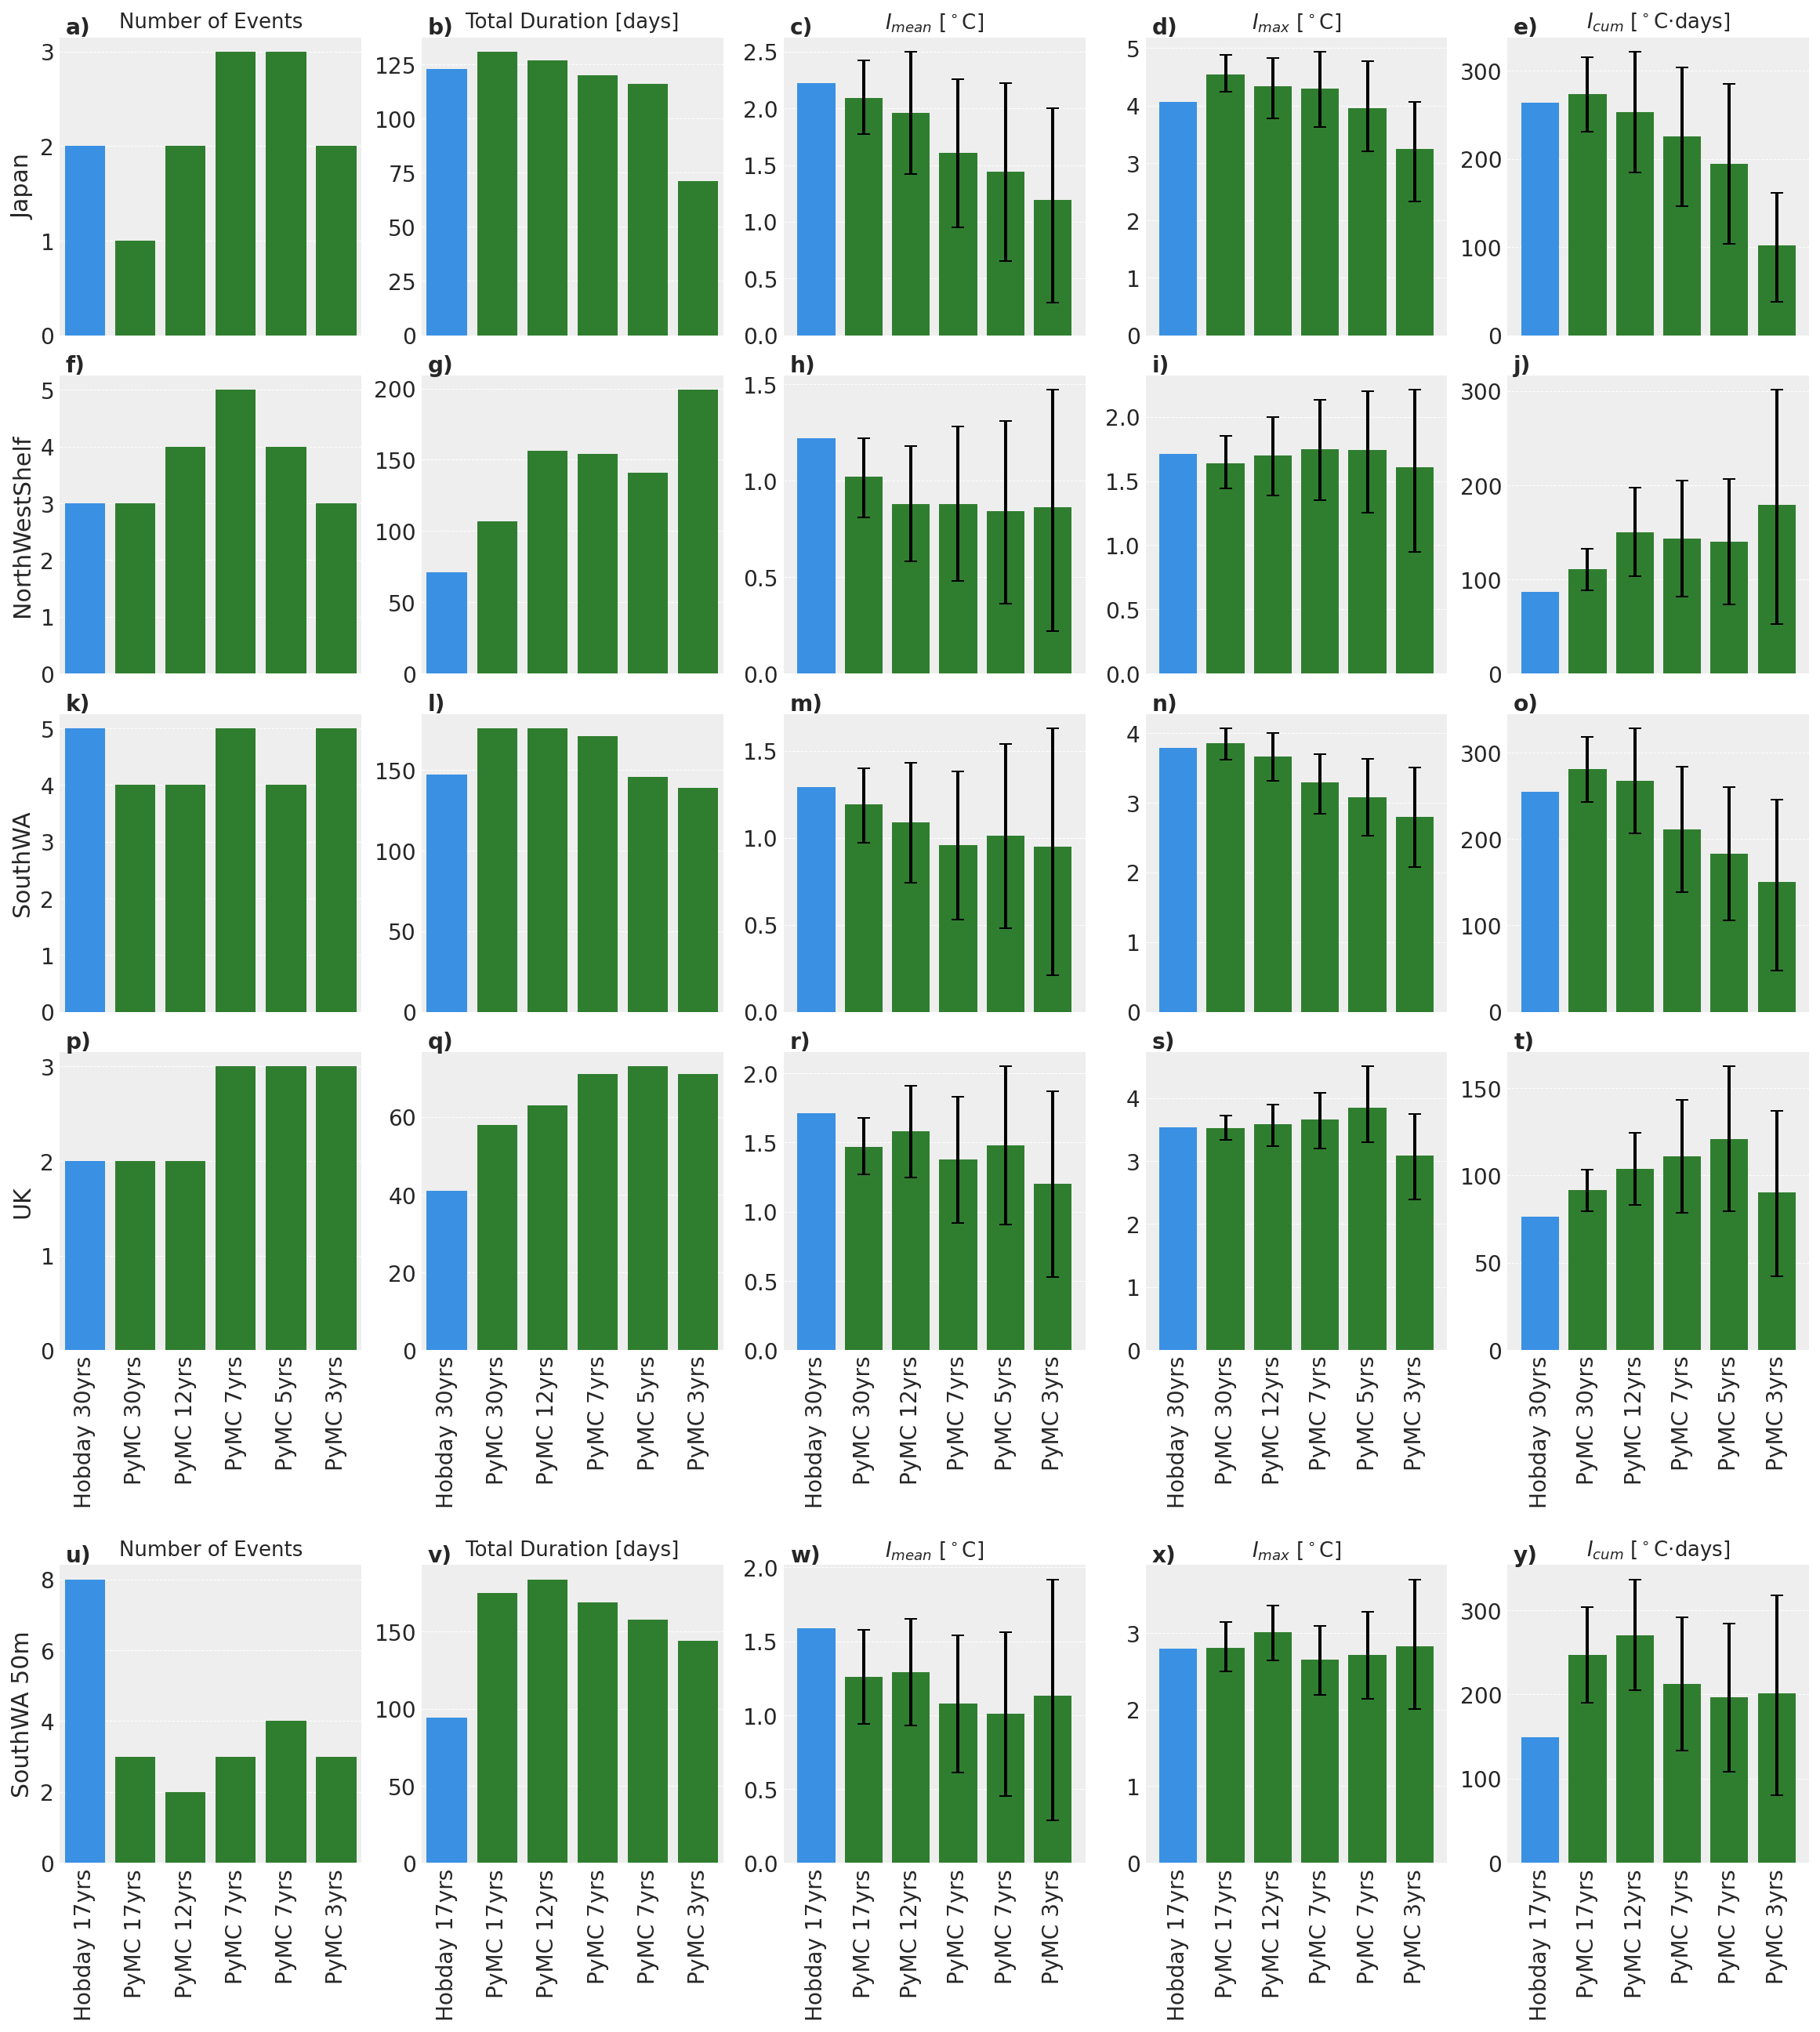

In [10]:
# Melt into long form
df_melted = all_metrics.melt(
    id_vars=["site", "method", "sub"],
    value_vars=[
        "n_events", "total_duration",
        "mean_intensity50", "max_intensity50", "cumulative_intensity50",
        "mean_intensity01", "max_intensity01", "cumulative_intensity01",
        "mean_intensity99", "max_intensity99", "cumulative_intensity99"
    ],
    var_name="metric",
    value_name="value"
)

# Define pretty labels
metric_labels = {
    "n_events": "Number of Events",
    "total_duration": "Total Duration [days]",
    "mean_intensity50": r"$I_{mean}$ [$^\circ$C]",
    "max_intensity50": r"$I_{max}$ [$^\circ$C]",
    "cumulative_intensity50": r"$I_{cum}$ [$^\circ$C$\cdot$days]",
    "mean_intensity01": r"$I_{mean}$ 0.01",
    "mean_intensity99": r"$I_{mean}$ 0.99",
    "max_intensity01": r"$I_{max}$ 0.01",
    "max_intensity99": r"$I_{max}$ 0.99",
    "cumulative_intensity01": r"$I_{cum}$ 0.01",
    "cumulative_intensity99": r"$I_{cum}$ 0.99",
}
df_melted["metric"] = df_melted["metric"].map(metric_labels)

# Drop duplicates (safety)
df_melted_unique = df_melted.drop_duplicates(
    subset=["site", "metric", "method", 'sub',"value"]
)
# Set site order
df_melted_unique["site"] = pd.Categorical( df_melted_unique["site"], categories=sites,ordered=True)

# Create label column
df_melted_unique["method_subset"] = df_melted_unique.apply(make_label, axis=1)

# Define metric order
metric_order = [
    "Number of Events",
    "Total Duration [days]",
    r"$I_{mean}$ [$^\circ$C]",
    r"$I_{max}$ [$^\circ$C]",
    r"$I_{cum}$ [$^\circ$C$\cdot$days]"
]

# Which need error bars
intensity_metrics = {
    r"$I_{mean}$ [$^\circ$C]": "mean_intensity",
    r"$I_{max}$ [$^\circ$C]": "max_intensity",
    r"$I_{cum}$ [$^\circ$C$\cdot$days]": "cumulative_intensity"
}

fig = plt.figure(
    figsize=(4 * len(metric_order), 4 * len(sites) + 1)
)

# 6 grid rows:
# row 1
# row 2
# row 3
# row 4
# spacer
# row 5

gs = GridSpec(
    nrows=6,
    ncols=len(metric_order),
    figure=fig,
    height_ratios=[1, 1, 1, 1, 0.45, 1],
    hspace=0.15
)

axes = np.empty((len(sites), len(metric_order)), dtype=object)

# First 4 rows
for i in range(4):
    for j in range(len(metric_order)):
        axes[i, j] = fig.add_subplot(gs[i, j])

# Last row, after the spacer
for j in range(len(metric_order)):
    axes[4, j] = fig.add_subplot(gs[5, j])
    
if len(sites) == 1:
    axes = np.array([axes])  # make consistent

for f, (site, site_df) in enumerate(df_melted_unique.groupby("site")):
    for ax, metric in zip(axes[f,:], metric_order):
        
        metric_df = site_df[site_df["metric"] == metric]
        metric_df = metric_df[::-1]
        metric_df.iloc[0], metric_df.iloc[1] = metric_df.iloc[1].copy(), metric_df.iloc[0].copy()

        # Plot baseline bars
        sns.barplot(
            data=metric_df,
            x="method_subset",
            y="value",
            ax=ax,
            hue="method",
            palette=['dodgerblue','forestgreen'],
            legend=False
        )

        # Add error bars for intensity metrics
        if metric in intensity_metrics.keys():
            base = intensity_metrics[metric]
            
            df50    = all_metrics[(all_metrics["site"] == site) & (all_metrics["method"] == "PyMC")][["sub", f"{base}50"]]
            df01_99 = all_metrics[(all_metrics["site"] == site) & (all_metrics["method"] == "PyMC")][["sub", f"{base}01", f"{base}99"]]
            
            merged = df50.merge(df01_99, on="sub", how="inner")
            merged = merged[::-1]
        
            y = merged[f"{base}50"].values
            yerr_lower =  merged[f"{base}01"].values - y
            yerr_upper =  y - merged[f"{base}99"].values
            
            x_positions = range(1, len(merged)+1)
            ax.errorbar(
                x=x_positions,
                y=y,
                yerr=[yerr_lower, yerr_upper],
                fmt="none",
                ecolor="black",
                elinewidth=2,
                capsize=4,
                zorder=10)


        # formatting
        if ax == axes[f,0]:
            ax.set_ylabel(f"{site}", fontsize=15)
        else:
            ax.set_ylabel("", fontsize=11)

        if f == 0 or f == 4:
            ax.set_title(metric, fontsize=13)
            
        else:
            ax.set_title("", fontsize=14)

        if f < 3: 
            ax.set_xticklabels('')
        elif f == 3: 
            ax.tick_params(axis="x", rotation=90)
        else: 
            ax.tick_params(axis="x", rotation=90)
            ax.set_xticklabels(['Hobday 17yrs','PyMC 17yrs','PyMC 12yrs','PyMC 7yrs','PyMC 7yrs', 'PyMC 3yrs'])
        
        ax.set_xlabel("", fontsize=11)
        
# Subplot labels
labels = [f"{ch})" for ch in string.ascii_lowercase[:len(axes.flat)]]
for ax, lab in zip(axes.flat, labels):
    ax.text(0.02, 1.07, lab,
            transform=ax.transAxes,
            fontsize=14,
            fontweight='bold',
            va='top', ha='left',
            bbox=dict(facecolor='white', alpha=0.0, edgecolor='none', pad=0))

plt.tight_layout()

# Save figures
plt.savefig(os.path.join(figures_folder, "Figure_10_5sites.pdf"), dpi=100, bbox_inches="tight")
plt.savefig(os.path.join(figures_folder, "Figure_10_5sites.png"), dpi=300, bbox_inches="tight")
plt.show()

In [11]:
summary_table = df_melted_unique.pivot_table(
    index=["site", "method_subset"],
    columns="metric",
    values="value",
    aggfunc="mean"
).reset_index()
summary_table#.to_csv("Figure_10_summary.csv", index=False)

C:\Users\24048369\AppData\Local\Temp\ipykernel_25460\2120574068.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  summary_table = df_melted_unique.pivot_table(


metric,site,method_subset,$I_{cum}$ 0.01,$I_{cum}$ 0.99,$I_{cum}$ [$^\circ$C$\cdot$days],$I_{max}$ 0.01,$I_{max}$ 0.99,$I_{max}$ [$^\circ$C],$I_{mean}$ 0.01,$I_{mean}$ 0.99,$I_{mean}$ [$^\circ$C],Number of Events,Total Duration [days]
0,Japan,Hobday 30yrs,NaN,NaN,263.84,NaN,NaN,4.06,NaN,NaN,2.22,2.0,123.0
1,Japan,PyMC 12yrs,321.75,184.85,253.25,4.88,3.83,4.33,2.5,1.42,1.96,2.0,127.0
2,Japan,PyMC 30yrs,315.45,231.09,273.3,4.84,4.2,4.54,2.41,1.76,2.09,1.0,131.0
3,Japan,PyMC 3yrs,165.4,41.91,101.5,4.15,2.42,3.24,2.09,0.38,1.19,2.0,71.0
4,Japan,PyMC 5yrs,285.61,103.54,194.47,4.7,3.13,3.95,2.23,0.66,1.44,3.0,116.0
5,Japan,PyMC 7yrs,304.2,147.1,225.38,4.97,3.66,4.3,2.27,0.96,1.61,3.0,120.0
6,NorthWestShelf,Hobday 30yrs,NaN,NaN,86.51,NaN,NaN,1.71,NaN,NaN,1.22,3.0,71.0
7,NorthWestShelf,PyMC 12yrs,196.76,102.99,149.99,2.01,1.4,1.7,1.18,0.58,0.88,4.0,156.0
8,NorthWestShelf,PyMC 30yrs,132.32,88.46,110.36,1.84,1.43,1.64,1.23,0.82,1.02,3.0,107.0
9,NorthWestShelf,PyMC 3yrs,306.59,57.65,179.41,2.27,1.01,1.61,1.5,0.25,0.86,3.0,199.0


In [12]:
# Melt your all_metrics into long form ---
df_melted = all_metrics.melt(
    id_vars=["site", "method", "sub"],
    value_vars=["n_events", "total_duration", "mean_intensity50", "max_intensity50", "cumulative_intensity50",
                                                "mean_intensity01", "max_intensity01", "cumulative_intensity01",
                                                "mean_intensity99", "max_intensity99", "cumulative_intensity99"],
    var_name="metric",
    value_name="value"
)

np.unique(df_melted.metric)
df_melted

# Define nice labels ---
metric_labels = {
    "n_events": "Number of Events",
    "total_duration": "Total Duration [days]",
    "mean_intensity50": r"$I_{mean}$ [$^\circ$C]",
    "max_intensity50": r"$I_{max}$ [$^\circ$C]",
    "cumulative_intensity50": r"$I_{cum}$ [$^\circ$C$\cdot$days]"
}
df_melted["metric"] = df_melted["metric"].map(metric_labels)

# Keep only ONE 30yrs Hobday entry per site ---
# (assumes duplicates exist in your all_metrics)
df_melted_unique = df_melted.drop_duplicates( subset=["site", "metric", "method",  "value"])
df_melted_unique

,site,method,sub,metric,value
0,Japan,Full 30yrs,3,Number of Events,2
1,Japan,PyMC,3,Number of Events,2
3,Japan,PyMC,5,Number of Events,3
9,Japan,PyMC,30,Number of Events,1
10,NorthWestShelf,Full 30yrs,3,Number of Events,3
...,...,...,...,...,...
541,SouthWA 50m,PyMC,3,NaN,83.82
543,SouthWA 50m,PyMC,5,NaN,108.44
545,SouthWA 50m,PyMC,7,NaN,133.83
547,SouthWA 50m,PyMC,12,NaN,204.54


## MHW Detectoin Timeseries 

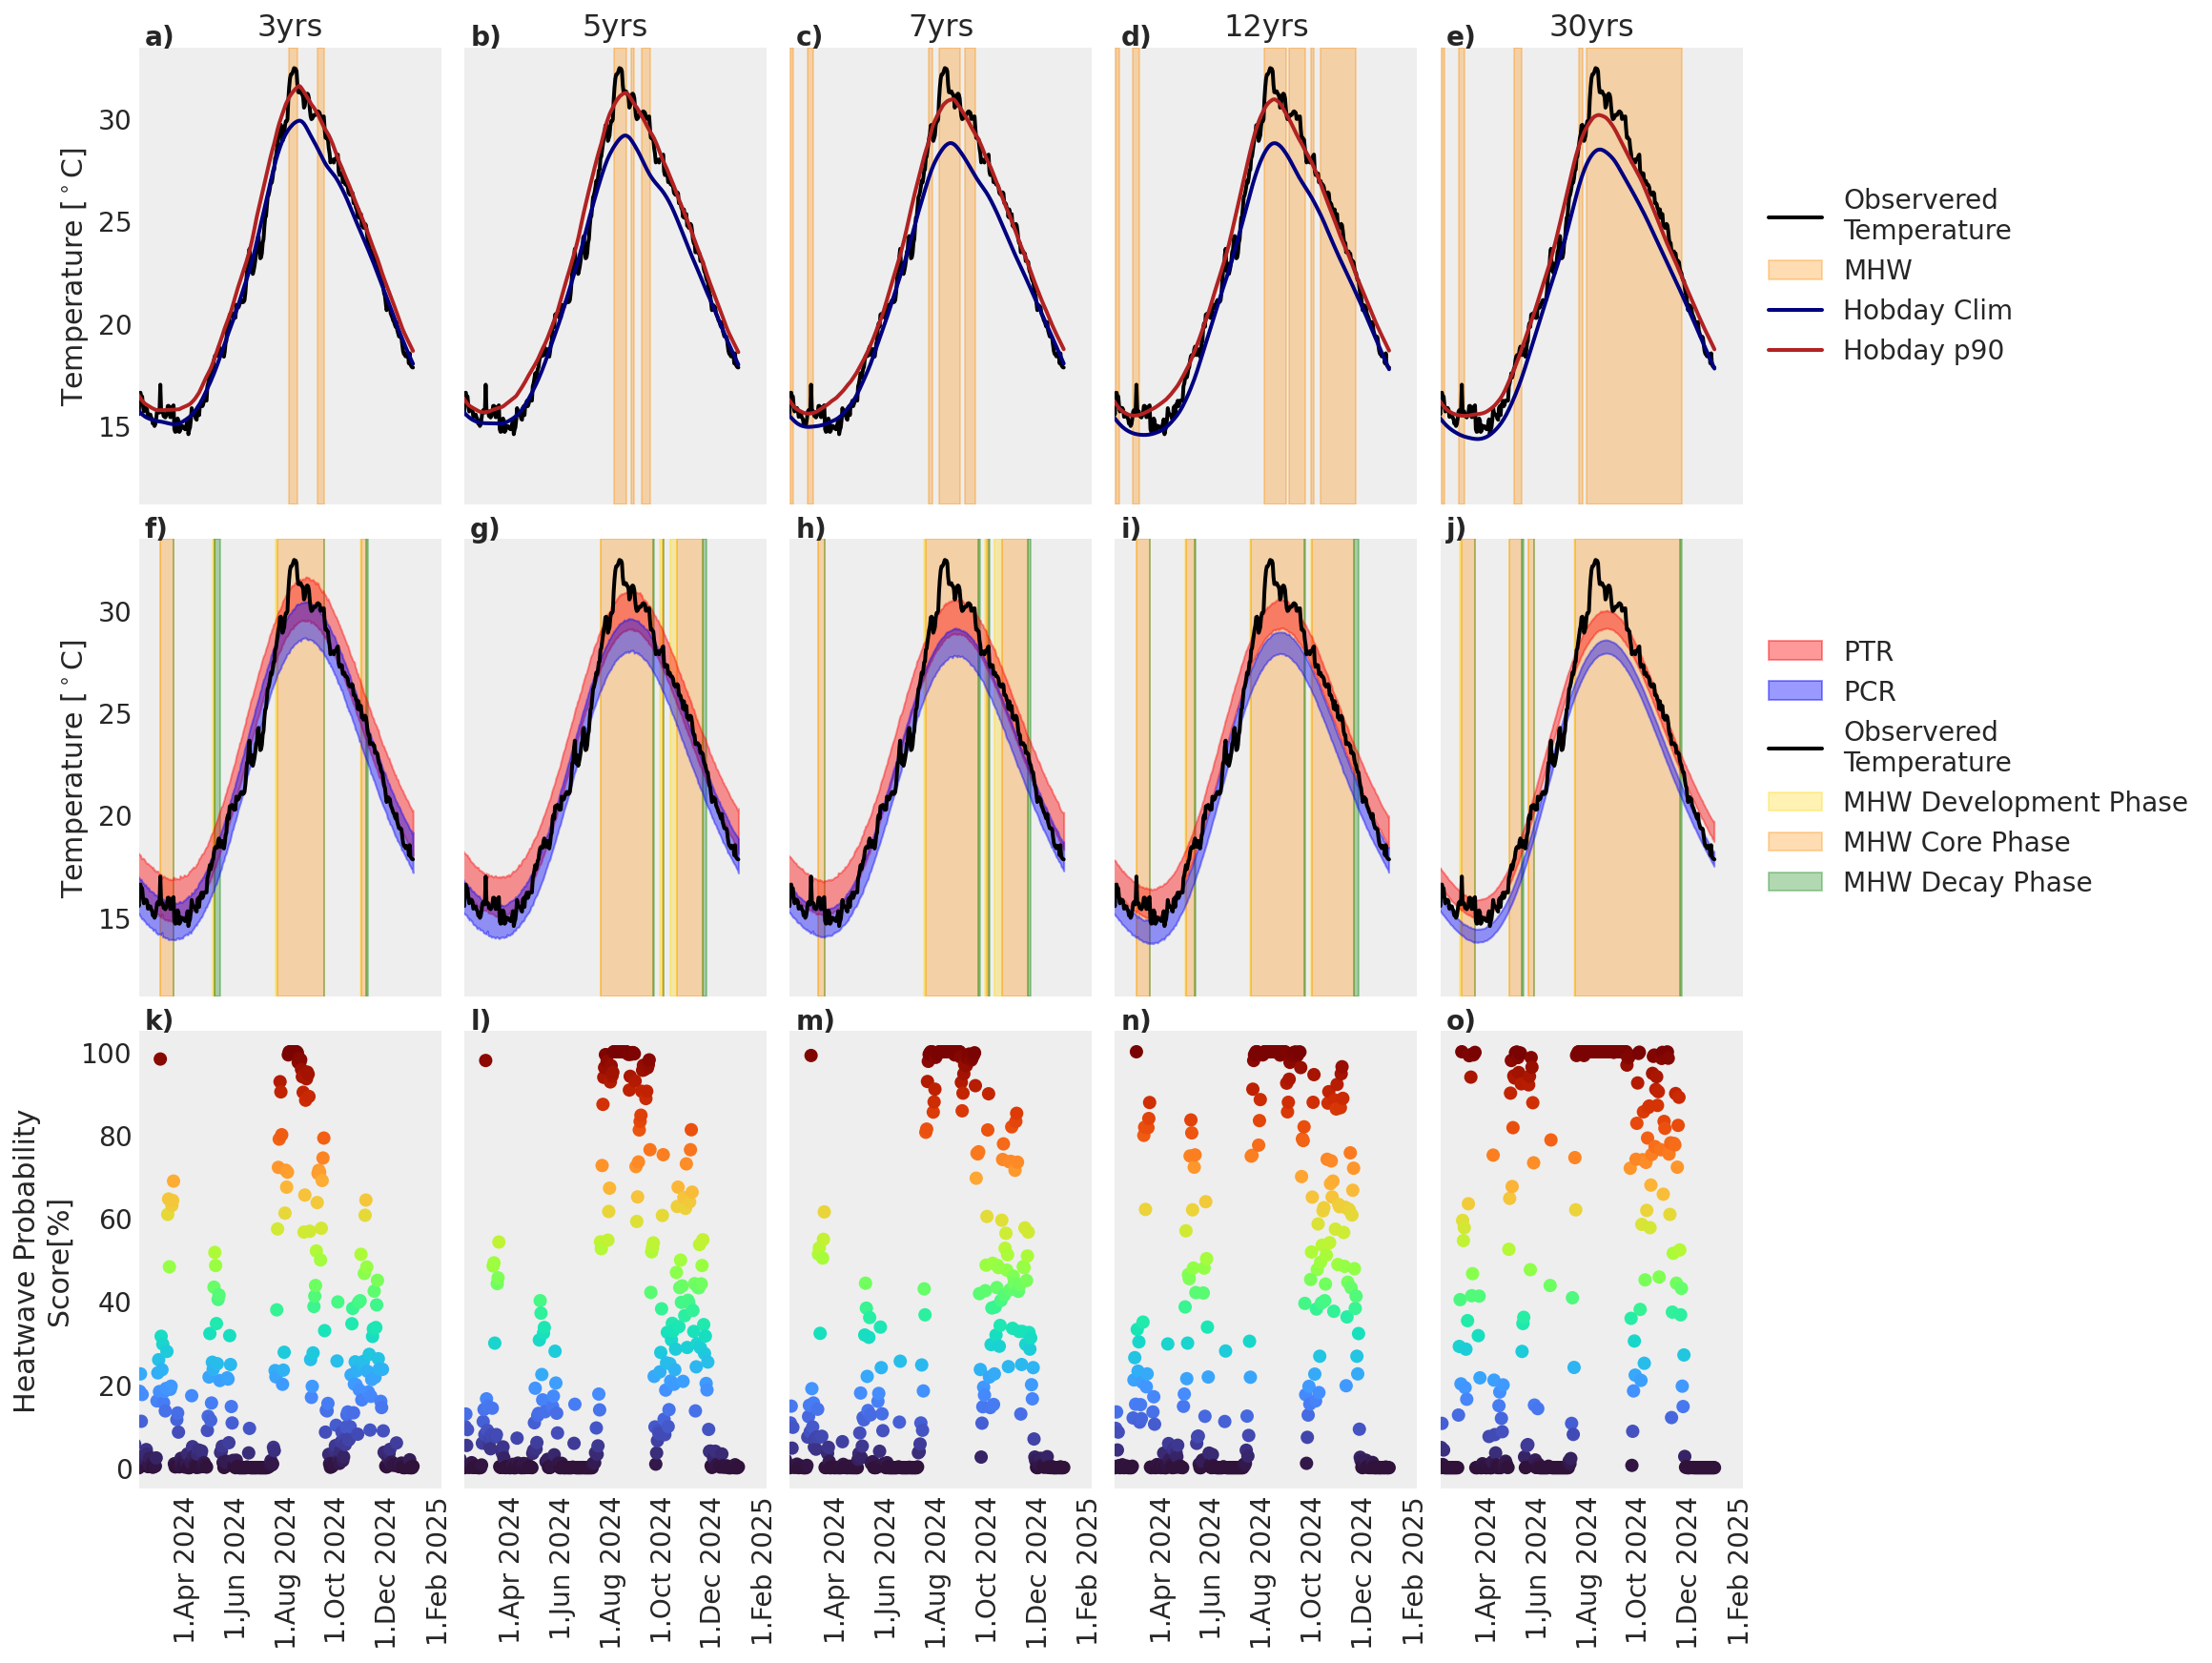

From 2024-02-03 to 2025-02-03


In [14]:
for i, site in enumerate(sites[:]):
    
    output_dir_site = os.path.join(figures_folder, site)

    # load Hobday climatology (30yrs reference)
    hobday = pd.read_csv( os.path.join(output_dir_site, "Daily_Hobday.csv"),index_col=0, parse_dates=True)
    mhw_dict_hobday_full = np.load(f"{output_dir_site}/30years_mhw_dict.npy",allow_pickle='TRUE').item()
    selected_date = pd.to_datetime(date_of_interest[site])
    
    f = 0
    fig, axs = plt.subplots(ncols = 5, nrows =3,  figsize=(16, 12) ,sharey='row', sharex = True  )
    axs = axs.flatten()
    axs[0].set_ylabel('Temperature [$^\\circ$C]')
    axs[5].set_ylabel('Temperature [$^\\circ$C]')
    axs[10].set_ylabel('Heatwave Probability\nScore[%]')
    for sub in subsets[:]:
    
        # load your OG timeseries for this subset
        og_timeseries = pd.read_pickle(f"{output_dir_site}/df_C_{sub}yrs.pkl")
        
        # load inference data for this subset
        idata = az.from_netcdf(os.path.join(output_dir_site, f"Idata_{sub}yrs.nc"))

        # calculate PCR & PTR and HPS
        PCR, PTR, time_array = get_PCRs_and_PTR(idata, og_timeseries)
        prob_PTR = calculate_prob_PTR(og_timeseries, PTR, variable="Temp")
    
        ax = axs[f]
        if site == 'SouthWA 50m' and sub == '30':
            ax.set_title(f'17yrs')
        else:
            ax.set_title(f'{sub}yrs')
        
        if sub != str(30):
            ax.plot(og_timeseries.index, og_timeseries.Temp, label = 'Observered\nTemperature', color = 'black', lw =2)
            mhw_small,clim_small,  timearray_small = comparing_to_Hobday(og_timeseries.Temp)
            for ds_start,ds_end in zip(mhw_small['date_start'][:-1],mhw_small['date_end'][:-1]):
                ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
            ax.axvspan(pd.Timestamp(mhw_small['date_start'][-1]), pd.Timestamp(mhw_small['date_end'][-1]), color='darkorange', alpha=0.3,label = 'MHW')
            ax.plot(og_timeseries.index, clim_small['seas'], color = 'navy', lw = 2, ls ='-', label= 'Hobday Clim - subset')
            ax.plot(og_timeseries.index, clim_small['thresh'], color = 'firebrick', lw = 2, ls ='-', label= 'Hobday p90 - subset')
        else:
            ax.plot(og_timeseries.index, og_timeseries.Temp, label = 'Observered\nTemperature', color = 'black', lw =2)
            
            for ds_start,ds_end in zip(mhw_dict_hobday_full['date_start'][:-1],mhw_dict_hobday_full['date_end'][:-1]):
                ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
            ax.axvspan(pd.Timestamp(mhw_dict_hobday_full['date_start'][-1]), pd.Timestamp(mhw_dict_hobday_full['date_end'][-1]), color='darkorange', alpha=0.3,label = 'MHW')
            ax.plot(hobday.index, hobday.seas, color = 'navy', lw = 2, label= 'Hobday Clim')
            ax.plot(hobday.index, hobday.thresh, color = 'firebrick', lw = 2, label= 'Hobday p90')

            mhw_small,clim_small,  timearray_small = comparing_to_Hobday(og_timeseries.Temp)
           
        ax = axs[f+5]
        plot_probs_range(PTR,time_array, ax, color = 'red', label = 'PTR', mean_line = False)
        plot_probs_range(PCR,time_array, ax, color = 'blue', label = 'PCR', mean_line = False)
        mhw_dict_hps = detect_mhws_from_hps(HPS=np.array(prob_PTR),T_obs=og_timeseries.Temp,PCR=PCR, PTR=PTR ,  time=og_timeseries.index,
                                            detection_threshold=50, ramp_threshold=20,  max_dip=5,  min_duration=5, merge_gap = 5)
        plot_mhw_phases(og_timeseries.Temp, np.array(prob_PTR), mhw_dict_hps, ax, detection_threshold=50, ramp_threshold=20)

        ax = axs[f+10]
        f += 1    
        ax.scatter(time_array, prob_PTR, c = prob_PTR, cmap = 'turbo')
       
    date_format = mdates.DateFormatter('1.%b %Y')  # On Windows use '%#d.%b'
    month_locator = mdates.MonthLocator(interval=2)   
    ax.set_xlim(selected_date - pd.Timedelta(days=180),  selected_date + pd.Timedelta(days=186))
    
    for ax in axs[:]:
        ax.xaxis.set_major_locator(month_locator)
        ax.xaxis.set_major_formatter(date_format)
        ax.tick_params(axis='x', rotation=90)  # Optional: rotate for better readability
        ax.grid()              

    
    ncols = 5
    nrows = 3
    legend_axes_indices = [(row + 1) * ncols - 1 for row in range(nrows)]  # last in each row
    
    for idx in legend_axes_indices:
        ax = axs[idx]
        handles, labels = ax.get_legend_handles_labels()
        if handles:  
            ax.legend( handles, labels,  loc="center left",   bbox_to_anchor=(1.05, 0.5),  borderaxespad=0, frameon=False )

    # generate subplot labels: a), b), c), ...
    labels = [f"{ch})" for ch in string.ascii_lowercase[:len(axs.flat)]]
    
    for ax, lab in zip(axs.flat, labels):
        ax.text(0.02, 1.05, lab,
                transform=ax.transAxes,
                fontsize=14,
                fontweight='bold',
                va='top', ha='left',
                bbox=dict(facecolor='white', alpha=0.0, edgecolor='none', pad=0))
  
    plt.savefig(os.path.join(output_dir_site, f"Figure_09.png"), dpi=300)
    plt.savefig(os.path.join(output_dir_site, f"Figure_09.pdf"), dpi=300)
    plt.show()

    print('From ' + str(selected_date - pd.Timedelta(days=180))[:10] +  ' to ' + str(selected_date + pd.Timedelta(days=186))[:10])

## Testing for example figure

C:\Users\24048369\AppData\Local\Temp\ipykernel_25460\1961948928.py:151: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 1, 0.95])


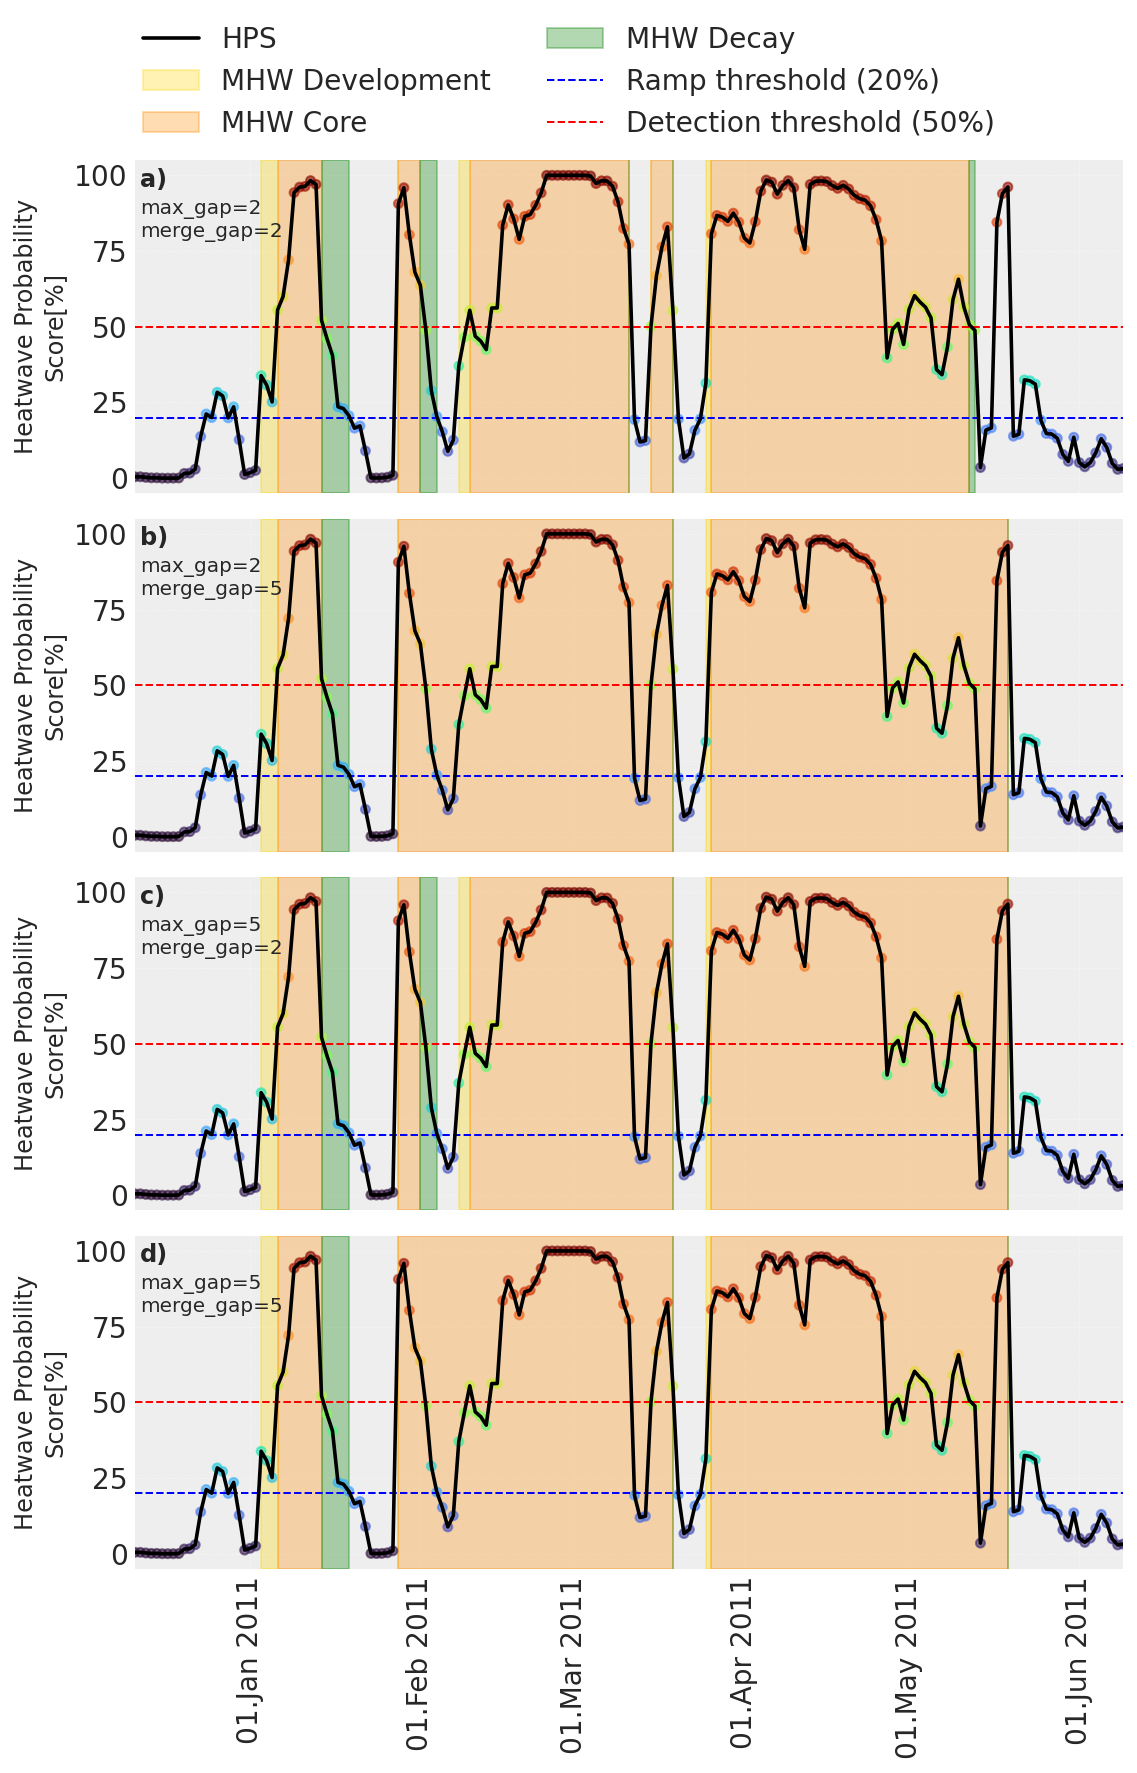

In [15]:
fig, axs = plt.subplots(4, 1, figsize=(8, 12), sharex=True, sharey=True)

subsets_example = ['3']
site = 'SouthWA'

param_sets = [
    {"max_gap": 2, "merge_gap": 2},
    {"max_gap": 2, "merge_gap": 5},
    {"max_gap": 5, "merge_gap": 2},
    {"max_gap": 5, "merge_gap": 5}
]

panel_labels = ['a', 'b', 'c', 'd']

all_handles = []
all_labels = []

for _, sub in enumerate(subsets_example):
    
    output_dir_site = os.path.join(figures_folder, site)
    selected_date = pd.to_datetime(date_of_interest[site])

    og_timeseries = pd.read_pickle(f"{output_dir_site}/df_C_{sub}yrs.pkl")
    idata = az.from_netcdf(os.path.join(output_dir_site, f"Idata_{sub}yrs.nc"))

    PCR, PTR, time_array = get_PCRs_and_PTR(idata, og_timeseries)
    prob_PTR = calculate_prob_PTR(og_timeseries, PTR, variable="Temp")

    HPS = pd.Series(np.asarray(prob_PTR).astype(float), index=og_timeseries.index)

    for col, params in enumerate(param_sets):

        ax = axs[col]
        max_gap = params["max_gap"]
        merge_gap = params["merge_gap"]
        mhw_dict = detect_mhws_from_hps(
            HPS=np.array(prob_PTR),
            T_obs=og_timeseries.Temp,
            PCR=PCR,
            PTR=PTR,
            time=og_timeseries.index,
            detection_threshold=50,
            ramp_threshold=20,
            max_dip=max_gap,
            min_duration=5,
            merge_gap=merge_gap
        )

        #  Main HPS line 
        line, = ax.plot( HPS.index, HPS,color="black", lw=1.8, label="HPS",  zorder=3)

        #  Events 
        for i, (start, end) in enumerate(zip(mhw_dict["date_start"], mhw_dict["date_end"])):
            event_mask = (HPS.index >= start) & (HPS.index <= end)
            hps_event = HPS[event_mask]
            if (hps_event >= 50).any():
                core_start = hps_event.index[hps_event >= 50][0]
                core_end   = hps_event.index[hps_event >= 50][-1]
            else:
                core_start, core_end = start, end
            dev_label = 'MHW Development' if i == 0 else None 
            core_label = 'MHW Core' if i == 0 else None 
            dec_label = 'MHW Decay' if i == 0 else None 
            
            ax.axvspan(start, core_start, color="gold", alpha=0.3, label=dev_label) 
            ax.axvspan(core_start, core_end, color="darkorange", alpha=0.3, label=core_label) 
            ax.axvspan(core_end, end, color="green", alpha=0.3, label=dec_label)

        # Scatter
        ax.scatter( time_array, prob_PTR, c=prob_PTR, cmap='turbo',  s=20, alpha=0.6,zorder=2 )

        # Threshold lines 
        r1 = ax.axhline(20, color='blue', linestyle='--', lw=1, label='Ramp threshold (20%)')
        r2 = ax.axhline(50, color='red', linestyle='--', lw=1, label='Detection threshold (50%)')
        
        ax.text(0.005, 0.92,f"{panel_labels[col]})",transform=ax.transAxes,
                fontsize=12,fontweight='bold')
        ax.text( 0.005, 0.77, f"max_gap={max_gap}\nmerge_gap={merge_gap}", transform=ax.transAxes, fontsize=10,)

        ax.grid(alpha=0.3)
        ax.set_ylabel( 'Heatwave Probability\nScore[%]',fontsize=12 )

        # collect legend handles only once
        if col == 0:
            handles, labels = ax.get_legend_handles_labels()
            all_handles = handles
            all_labels = labels

# shared x formatting
for ax in axs:
    ax.set_xlim(selected_date - pd.Timedelta(days=80), selected_date + pd.Timedelta(days=100))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%b %Y'))
    ax.tick_params(axis='x', rotation=90)

# legend (top, outside) 
fig.legend(all_handles, all_labels,loc="upper center", ncol=2, frameon=False,bbox_to_anchor=(0.5, 1.03))

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(os.path.join(output_dir_site, f"Figure_03.png"), dpi=300) 
plt.savefig(os.path.join(output_dir_site, f"Figure_03.pdf"), dpi=300)
plt.show()


# Sensitivity analysis HPS algorithm

In [14]:
site = "SouthWA"
sub = "3"

output_dir_site = os.path.join(figures_folder, site)
og_timeseries = pd.read_pickle(f"{output_dir_site}/df_C_{sub}yrs.pkl")
idata = az.from_netcdf( os.path.join(output_dir_site, f"Idata_{sub}yrs.nc"))

PCR, PTR, time_array = get_PCRs_and_PTR(idata,og_timeseries)
prob_PTR = calculate_prob_PTR( og_timeseries, PTR, variable="Temp")
HPS = np.asarray(prob_PTR)

## Sensitivity 1: HPS detection threshold

In [15]:
results_threshold = []
for threshold in np.arange(10,100,10):
    mhw = run_hps_detection_sensitivity(
        HPS,
        PCR,
        PTR,
        og_timeseries,
        detection_threshold=threshold,
        ramp_threshold=20,
        max_gap=5,
        merge_gap=5
    )

    metrics = calculate_event_metrics(mhw)
    metrics["threshold"] = threshold
    results_threshold.append(metrics)
    
df_threshold = pd.DataFrame(results_threshold)

## Sensitivity 2: Ramp threshold

In [17]:
results_ramp = []
for ramp in np.arange(5, 55,5):
    mhw = run_hps_detection_sensitivity(
        HPS,
        PCR,
        PTR,
        og_timeseries,
        detection_threshold=50,
        ramp_threshold=ramp,
        max_gap=5,
        merge_gap=5 )

    metrics = calculate_event_metrics(mhw)
    metrics["ramp_threshold"] = ramp
    results_ramp.append(metrics)

df_ramp = pd.DataFrame(results_ramp)

## Sensitivity 3: max_gap / merge_gap

In [19]:
results_gap = []
for max_gap in range(1,21):
    for merge_gap in range(1,21):
        mhw = run_hps_detection_sensitivity(
            HPS,
            PCR,
            PTR,
            og_timeseries,
            detection_threshold=50,
            ramp_threshold=20,
            max_gap=max_gap,
            merge_gap=merge_gap
        )
        metrics = calculate_event_metrics(mhw)
        metrics["max_gap"] = max_gap
        metrics["merge_gap"] = merge_gap
        results_gap.append(metrics)

df_gap = pd.DataFrame(results_gap)

In [21]:
df_gap.pivot( index="max_gap",columns="merge_gap",values="n_events")

merge_gap,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
max_gap,,,,,,,,,,,,,,,,,,,,
1,9,8,9,7,7,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4
2,8,8,9,7,7,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4
3,8,8,8,7,7,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4
4,8,8,8,7,7,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4
5,8,8,8,7,7,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4
6,7,7,7,6,6,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4
7,7,7,7,6,6,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4
8,6,6,6,6,6,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4
9,6,6,6,6,6,6,6,6,5,4,4,4,4,4,4,4,4,4,4,4


## default event and overlap with default event

In [22]:
default_mhw = run_hps_detection_sensitivity( HPS, PCR, PTR,og_timeseries)

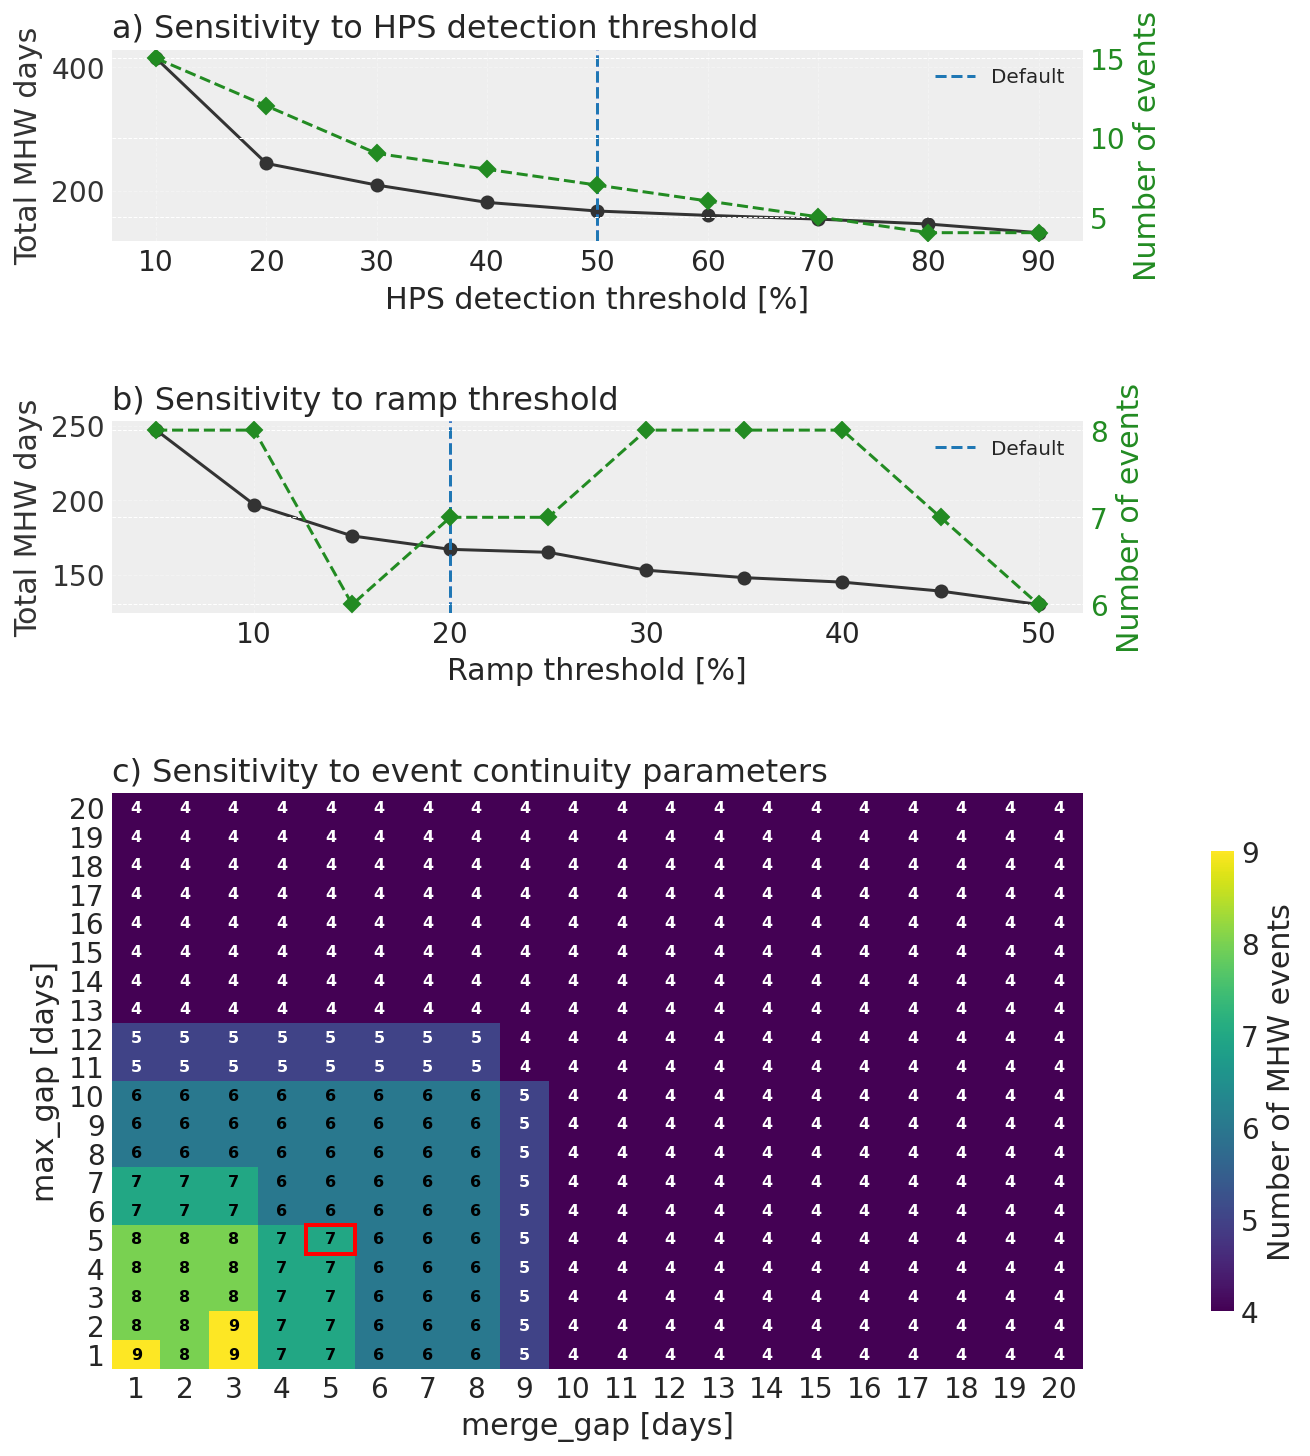

In [26]:
fig, axs = plt.subplots( 3, 1,figsize=(9, 10),gridspec_kw={"height_ratios": [0.6, 0.6, 1.8], 'hspace':0.15},constrained_layout=True)

two_axis_plot(axs[0],df_threshold["threshold"], df_threshold, "HPS detection threshold [%]","a) Sensitivity to HPS detection threshold",50)
axs[0].axvline( 50,  color="tab:blue",linestyle="--",linewidth=1.5, label="Default")
axs[0].legend(loc = 'upper right', fontsize = 10)

two_axis_plot( axs[1], df_ramp["ramp_threshold"], df_ramp,"Ramp threshold [%]", "b) Sensitivity to ramp threshold", 20)
axs[1].axvline( 20,  color="tab:blue", linestyle="--", linewidth=1.5, label="Default")
axs[1].legend(loc = 'upper right', fontsize = 10)

# Heatmap
ax = axs[2]
pivot_gap = df_gap.pivot(index="max_gap", columns="merge_gap",  values="n_events")
cmap = plt.get_cmap("viridis")
im = ax.imshow(pivot_gap.values,cmap=cmap,origin="lower",aspect="auto")

# Highlight 'default' settings
default_max_gap = 5
default_merge_gap = 5
row = np.where(pivot_gap.index == default_max_gap)[0][0]
col = np.where(pivot_gap.columns == default_merge_gap)[0][0]

# draw rectangle around the default cell
rect = plt.Rectangle( (col - 0.5, row - 0.5), 1, 1, fill=False,edgecolor="red",linewidth=2)
ax.add_patch(rect)


ax.set_xticks(np.arange(len(pivot_gap.columns)))
ax.set_xticklabels(pivot_gap.columns)
ax.set_yticks(np.arange(len(pivot_gap.index)))
ax.set_yticklabels(pivot_gap.index)
ax.grid(False)
ax.set_xlabel("merge_gap [days]")
ax.set_ylabel("max_gap [days]")
ax.set_title("c) Sensitivity to event continuity parameters", loc="left")

# dynamic text color based on background
norm = im.norm  # normalization used by imshow
for i in range( pivot_gap.values.shape[0]):
    for j in range( pivot_gap.values.shape[1]):
        value =  pivot_gap.values[i, j]
        normalized = norm(value)
        text_color = "white" if normalized < 0.35 else "black"
        ax.text( j, i, f"{int(value)}", ha="center",  va="center", color=text_color, fontsize=8,fontweight="bold")

cbar = fig.colorbar( im,ax=ax,shrink=0.8)
cbar.set_label("Number of MHW events")

fig.savefig("figure_sensitivity.png", dpi=300)
plt.show()

# More MCMC diagnostics 

In [23]:
# Get a clean summary dataframe of R-hat, Bulk ESS, and Tail ESS
target_params = ["alpha", "sigma", "beta_fourier"]
summary_df = az.summary(idata, var_names=target_params, kind="diagnostics")
core_params = summary_df[~summary_df.index.str.contains("likelihood_unobserved", na=False)]

print(core_params[["r_hat", "ess_bulk", "ess_tail"]])

# Check the absolute minimum tail ESS across ALL parameters
min_tail_ess = core_params["ess_tail"].min()
print(f"Your lowest Tail ESS is: {min_tail_ess}")

                 r_hat  ess_bulk  ess_tail
alpha             1.00    5307.0    1249.0
sigma             1.00    2687.0    1326.0
beta_fourier[0]   1.00    4787.0    1470.0
beta_fourier[1]   1.01    5476.0    1538.0
beta_fourier[2]   1.00    5867.0    1457.0
beta_fourier[3]   1.00    5372.0    1594.0
Your lowest Tail ESS is: 1249.0


In [25]:
diagnostic_records = []

for i, site in enumerate(sites[-1:]):
    output_dir_site = os.path.join(figures_folder, site)
    for sub in subsets[:]:
        
        file_path = os.path.join(output_dir_site, f"Idata_{sub}yrs.nc")
            
        if not os.path.exists(file_path):
            print(f"Data not find: {file_path}")
            continue
            
        # Inference Data 
        idata = az.from_netcdf(file_path)
        # Divergences 
        total_divergences = idata.sample_stats["diverging"].sum().item()
        
        # Chains and Draws 
        num_chains = idata.posterior.sizes["chain"]
        num_draws = idata.posterior.sizes["draw"]
        total_draws = num_chains * num_draws
        
        # Acceptance Rate 
        if "mean_tree_accept" in idata.sample_stats:
            mean_accept_rat = idata.sample_stats["mean_tree_accept"].mean().item()
        elif "acceptance_rate" in idata.sample_stats:
            mean_accept_rat = idata.sample_stats["acceptance_rate"].mean().item()
        else:
            mean_accept_rat = float('nan')
        
        # Diagnostics (R-hat and Tail-ESS)
        summary_df = az.summary(idata, var_names=target_params, kind="diagnostics")
        core_params = summary_df[~summary_df.index.str.contains("likelihood_unobserved", na=False)]
        
        max_rhat = core_params["r_hat"].max()
        min_tail_ess = core_params["ess_tail"].min()
        min_bulk_ess = core_params["ess_bulk"].min()
        
        record = {
            "Site": site,
            "Subset (Yrs)": sub,
            "Chains": num_chains,
            "Draws/Chain": num_draws,
            "Total Draws": total_draws,
            "Mean Accept Rate": round(mean_accept_rat, 4),
            "Divergences": total_divergences,
            "Max R-hat": round(max_rhat, 4),
            "Min Tail-ESS": round(min_tail_ess, 1),
            "Min Bulk-ESS": round(min_bulk_ess, 1)
        }
        
        diagnostic_records.append(record)
        print(f"Successful: Site={site}, Subset={sub}")


df_diagnostics = pd.DataFrame(diagnostic_records)

print("\n--- Globale MCMC Diagnostik Tabelle ---")
print(df_diagnostics.to_string(index=False))


Successful: Site=SouthWA 50m, Subset=3
Successful: Site=SouthWA 50m, Subset=5
Successful: Site=SouthWA 50m, Subset=7
Successful: Site=SouthWA 50m, Subset=12
Successful: Site=SouthWA 50m, Subset=30

--- Globale MCMC Diagnostik Tabelle ---
       Site Subset (Yrs)  Chains  Draws/Chain  Total Draws  Mean Accept Rate  Divergences  Max R-hat  Min Tail-ESS  Min Bulk-ESS
SouthWA 50m            3       4          500         2000            0.8100            0       1.01        1398.0        2547.0
SouthWA 50m            5       4          500         2000            0.8093            0       1.01        1346.0        3116.0
SouthWA 50m            7       4          500         2000            0.8208            0       1.00        1449.0        2836.0
SouthWA 50m           12       4          500         2000            0.8024            0       1.01        1154.0        4220.0
SouthWA 50m           30       4          500         2000            0.8058            0       1.01        1249.0   